
# Assignment 2 — Task 2
## Heart Disease Prediction System

**Course:** Machine Learning Fundamentals (AIC354)

**Live Deployment Link:**

https://heart-disease-prediction-suleman1208sp24-bai-051.streamlit.app/


## Introduction

**Course:** Machine Learning Fundamentals (AIC354) | **Assignment 2** | COMSATS University Islamabad, Lahore Campus

This notebook follows the same steps as the Titanic Passenger Survival Prediction System. Only the data and the 4 input attributes are different.

##### **Definition**
A binary classification ML task. It predicts whether a patient has heart disease (Yes) or does not have heart disease (No), using only 4 attributes of the patient.

##### **Application**
It helps to learn how a machine learning system is built from start to end. A system like this could help a doctor do a quick first check. It does NOT replace a doctor.

## Input and Output

### Inputs (only 4 attributes, as the assignment requires)

| **Input Feature/Attribute** | **Possible Values** |
| --- | --- |
| **ChestPain** (type of chest pain) | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **ExerciseAngina** (chest pain during exercise) | Yes, No |
| **Vessels** (number of major blood vessels seen in fluoroscopy) | Zero, One, Two, Three |
| **Thal** (thalassemia blood test result) | Normal, Fixed Defect, Reversible Defect |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | Yes, No |

### Examples

| ChestPain | ExerciseAngina | Vessels | Thal | HeartDisease |
| :--- | :---: | :---: | :--- | :---: |
| Typical Angina | No | Zero | Fixed Defect | No |
| Asymptomatic | Yes | Three | Normal | Yes |
| Asymptomatic | Yes | Two | Reversible Defect | Yes |
| Non-Anginal Pain | No | Zero | Normal | No |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | YOUR NAME (YOUR REG. NO.) |
| **IDE** | Google Colab (Jupyter Notebook) |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, Pickle, scikit-learn, PrettyTable, Matplotlib, Seaborn |
| **Dataset** | Heart Disease Data Set, UCI Machine Learning Repository (Cleveland file): https://archive.ics.uci.edu/dataset/45/heart+disease |
| **Date of Completion** | 18-Oct-2026 |

##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)
  - Step 5.1: Train the Label Encoder
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 7.2: Load the Saved Model
  - Step 7.3: Evaluate the Machine Learning Model
    - Step 7.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - **Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) — NEW**
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from User
  - Step 8.2: Convert User Input into Feature Vector
  - Step 8.3: Label Encoding of Feature Vector
  - Step 8.4: Load the Saved Model
  - Step 8.5: Model Prediction
    - Step 8.5.1: Apply Model and Return Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Make a List of Potential Improvements
  - Step 9.3: Improve the Model Based on Feedback
- **Step 10: Deploy Your Model as a Public Web App**


## Code – Heart Disease Prediction

###  Step 1: Import Libraries

In [26]:
%pip install -q prettytable

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns


### Step 1.1: Prepare the Heart Disease Data
The Titanic notebook started with a ready `sample-data.csv`. For heart disease we make it ourselves from the raw UCI file `processed.cleveland.data`.

**In Google Colab:** upload `processed.cleveland.data` first (folder icon on the left, then the upload icon).

In [28]:
import os
import pandas as pd

# Stop with a clear message if the raw data file was not uploaded
assert os.path.exists("processed.cleveland.data"), "Upload processed.cleveland.data first (folder icon on the left)"

# The raw file has no header row, so we give the column names (from the UCI documentation).
# Missing values are written as "?" in the file.
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
raw = pd.read_csv("processed.cleveland.data", header=None, names=cols, na_values="?")
print("Rows in raw data:", len(raw))

# Remove rows with missing values (ca has 4, thal has 2)
clean = raw.dropna().reset_index(drop=True)
print("Rows after removing missing values:", len(clean))

# Keep only the 4 chosen inputs, change number codes into words, and make the output Yes/No
data = pd.DataFrame({
    "ChestPain": clean["cp"].map({1: "Typical Angina", 2: "Atypical Angina", 3: "Non-Anginal Pain", 4: "Asymptomatic"}),
    "ExerciseAngina": clean["exang"].map({0: "No", 1: "Yes"}),
    "Vessels": clean["ca"].map({0: "Zero", 1: "One", 2: "Two", 3: "Three"}),
    "Thal": clean["thal"].map({3: "Normal", 6: "Fixed Defect", 7: "Reversible Defect"}),
    "HeartDisease": (clean["num"] > 0).map({False: "No", True: "Yes"}),
})

# Save as sample-data.csv (Step 2 will load this file)
data.to_csv("sample-data.csv", index=False)
print("Saved: sample-data.csv")
print(data.head())

Rows in raw data: 303
Rows after removing missing values: 297
Saved: sample-data.csv
          ChestPain ExerciseAngina Vessels               Thal HeartDisease
0    Typical Angina             No    Zero       Fixed Defect           No
1      Asymptomatic            Yes   Three             Normal          Yes
2      Asymptomatic            Yes     Two  Reversible Defect          Yes
3  Non-Anginal Pain             No    Zero             Normal           No
4   Atypical Angina             No    Zero             Normal           No


### Step 2: Load Sample Data

In [29]:
"""
Purpose of this section:
-------------------------
This part of the code loads a sample dataset from a CSV file into a
pandas DataFrame. It then displays the dataset so that students can
see the raw data being used for further processing and model training.
"""

# Read the CSV file and load it into a pandas DataFrame
# 'sample-data.csv' should be present in the working directory
sample_data = pd.read_csv("sample-data.csv")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)




Sample Data:

            ChestPain ExerciseAngina Vessels               Thal HeartDisease
0      Typical Angina             No    Zero       Fixed Defect           No
1        Asymptomatic            Yes   Three             Normal          Yes
2        Asymptomatic            Yes     Two  Reversible Defect          Yes
3    Non-Anginal Pain             No    Zero             Normal           No
4     Atypical Angina             No    Zero             Normal           No
5     Atypical Angina             No    Zero             Normal           No
6        Asymptomatic             No     Two             Normal          Yes
7        Asymptomatic            Yes    Zero             Normal           No
8        Asymptomatic             No     One  Reversible Defect          Yes
9        Asymptomatic            Yes    Zero  Reversible Defect          Yes
10       Asymptomatic             No    Zero       Fixed Defect           No
11    Atypical Angina             No    Zero             Nor

### Step 3: Understand and Pre-process Sample Data

####  Step 3.1: Understand Sample Data

In [30]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(sample_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", sample_data["ChestPain"].count())
print("========================================\n")




Attributes in Sample Data:

Index(['ChestPain', 'ExerciseAngina', 'Vessels', 'Thal', 'HeartDisease'], dtype='str')


Number of Instances in Sample Data: 297



#### Step 3.2: Pre-process Sample Data
Pre-processing was needed. The data cell above (Step 1.1) did these 4 things:
1. Removed 6 rows that had missing values (`ca` has 4 missing, `thal` has 2 missing). 297 rows are left.
2. Made the output two classes: 0 = **No** heart disease, 1 to 4 = **Yes** heart disease.
3. Changed the number codes into words (the same way Titanic uses First / Second / Third), so Label Encoding in Step 5 has real categories to work on.
4. Saved the clean data as `sample-data.csv`.

#### Step 4: Feature Extraction
The raw data has 13 input attributes. The assignment says to use **only 4**, so feature extraction was needed.

**How the 4 were chosen:** I tried all combinations of 4 from the 8 category-type attributes (sex, cp, fbs, restecg, exang, slope, ca, thal) using 5-fold cross-validation with the same SVC model. The best set was **cp, exang, ca, thal** (about 84% cross-validation accuracy). The numeric attributes (age, trestbps, chol, thalach, oldpeak) were not used, because Label Encoding works on categories, as in the Titanic notebook.

| Selected attribute | Name used here | Meaning |
| --- | --- | --- |
| cp | ChestPain | Type of chest pain |
| exang | ExerciseAngina | Chest pain caused by exercise |
| ca | Vessels | Number of major vessels seen in fluoroscopy |
| thal | Thal | Thalassemia blood test result |

### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [31]:
"""
Purpose of this section:
-------------------------
This part of the code sets up and trains Label Encoders.
Label Encoding is used to convert categorical values (like 'Yes', 'No', 'Zero', 'Asymptomatic')
into numeric codes that machine learning algorithms can work with.

Steps:
1. Define sample label categories for each attribute.
2. Initialize a LabelEncoder for each attribute.
3. Train (fit) each LabelEncoder with its respective category values.
"""

# Define label categories for each feature
# These are possible values each column can have in the dataset
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": ["Yes", "No"]})
vessels = pd.DataFrame({"Vessels": ["Zero", "One", "Two", "Three"]})
thal = pd.DataFrame({"Thal": ["Normal", "Fixed Defect", "Reversible Defect"]})
heartdisease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
chestpain_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
vessels_label_encoder = LabelEncoder()
thal_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
vessels_label_encoder.fit(np.ravel(vessels))
thal_label_encoder.fit(np.ravel(thal))
heartdisease_label_encoder.fit(np.ravel(heartdisease))


Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[object](2,)","['No','Yes']"


#### Step 5.2: Label Encode the Output

In [32]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the target/output variable
("HeartDisease") in the dataset. The categorical values ("Yes", "No") are
converted into numerical values (e.g., 1 and 0) that can be used by
machine learning algorithms.
"""

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "HeartDisease" (categorical -> numeric) using the trained LabelEncoder
print("\n\nHeartDisease Attribute After Label Encoding:")
print("========================================\n")
sample_data["encoded_heartdisease"] = heartdisease_label_encoder.transform(sample_data['HeartDisease'])

# Show original "HeartDisease" values and their numeric encodings
print(sample_data[["HeartDisease", "encoded_heartdisease"]])

# Replace original categorical columns with encoded values for the output dataset
sample_data_encoded_output[['ChestPain', 'ExerciseAngina', 'Vessels', 'Thal', 'HeartDisease']] = \
    sample_data[['ChestPain', 'ExerciseAngina', 'Vessels', 'Thal', 'encoded_heartdisease']]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r'sample-data-encoded-output.csv', index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")




HeartDisease Attribute After Label Encoding:

    HeartDisease  encoded_heartdisease
0             No                     0
1            Yes                     1
2            Yes                     1
3             No                     0
4             No                     0
5             No                     0
6            Yes                     1
7             No                     0
8            Yes                     1
9            Yes                     1
10            No                     0
11            No                     0
12           Yes                     1
13            No                     0
14            No                     0
15            No                     0
16           Yes                     1
17            No                     0
18            No                     0
19            No                     0
20            No                     0
21            No                     0
22           Yes                     1
23           Yes

#### Step 5.3: Label Encode the Input

In [33]:
"""
Purpose of this section:
-------------------------
This part of the code applies Label Encoding to the input features
("ChestPain", "ExerciseAngina", "Vessels", "Thal"). Each categorical value
is converted into a numeric value so that machine learning models
can process them.
"""

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input attribute
sample_data_encoded_output["encoded_chestpain"] = chestpain_label_encoder.transform(sample_data_encoded_output['ChestPain'])
sample_data_encoded_output["encoded_exerciseangina"] = exerciseangina_label_encoder.transform(sample_data_encoded_output['ExerciseAngina'])
sample_data_encoded_output["encoded_vessels"] = vessels_label_encoder.transform(sample_data_encoded_output['Vessels'])
sample_data_encoded_output["encoded_thal"] = thal_label_encoder.transform(sample_data_encoded_output['Thal'])

# Replace categorical columns with encoded values in the dataset
sample_data_encoded[['ChestPain', 'ExerciseAngina', 'Vessels', 'Thal', 'HeartDisease']] = \
    sample_data_encoded_output[['encoded_chestpain', 'encoded_exerciseangina', 'encoded_vessels', 'encoded_thal', 'HeartDisease']]

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r'sample-data-encoded.csv', index=False, header=True)




Sample Data after Label Encoding:

     ChestPain  ExerciseAngina  Vessels  Thal  HeartDisease
0            3               0        3     0             0
1            0               1        1     1             1
2            0               1        2     2             1
3            2               0        3     1             0
4            1               0        3     1             0
5            1               0        3     1             0
6            0               0        2     1             1
7            0               1        3     1             0
8            0               0        0     2             1
9            0               1        3     2             1
10           0               0        3     0             0
11           1               0        3     1             0
12           2               1        0     0             1
13           1               0        3     2             0
14           2               0        3     2             0
15 

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [34]:
"""
Purpose of this section:
-------------------------
This part of the code splits the dataset into Training Data and Testing Data.
- Training Data is used to teach the machine learning model.
- Testing Data is used to check how well the model performs on unseen data.
"""

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# stratify keeps the same Yes/No balance of HeartDisease in both the training and the testing data
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    stratify=sample_data_encoded["HeartDisease"]
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r'training-data-encoded.csv', index=False, header=True)
testing_data_encoded.to_csv(r'testing-data-encoded.csv', index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)


Training Data shape: (237, 5)
Testing Data shape: (60, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [35]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (input vectors) and
the labels (output values) from the training dataset.
"""

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)


Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


### 6.3: Train the Support Vector Classifier

In [36]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the training data.
The SVC is a type of machine learning model that finds the best boundary
to separate different classes (e.g., heart disease vs. no heart disease).
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma='auto', random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [37]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC)
model to your computer so it can be reused later without retraining.
"""

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print("Saved: svc_trained_model.pkl")


Saved: svc_trained_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [38]:
"""
Purpose of this section:
-------------------------
This part of the code separates the features (inputs) and the labels (outputs)
from the testing dataset.
"""

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)


Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


### Step 7.2: Load the Saved Model

In [39]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from disk into memory.
"""

model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print("Model loaded from svc_trained_model.pkl")


Model loaded from svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Models on Testing Data

In [40]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the testing data.
"""

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r'model-predictions.csv', index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)




Predictions Returned by svc_trained_model:

     ChestPain  ExerciseAngina  Vessels  Thal  HeartDisease  Predictions
69           2               0        3     1             1            0
2            0               1        2     2             1            1
94           0               1        0     2             1            1
119          0               1        2     2             1            1
266          0               1        0     2             1            1
264          0               0        3     2             1            1
281          0               0        1     0             1            1
36           0               1        3     2             1            1
282          0               1        2     0             1            1
192          0               1        2     1             1            1
271          3               0        3     2             0            0
230          1               1        0     1             0            1
149  

### Step 7.4: Calculate the Accuracy Score

In [41]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
testing dataset.
"""

model_accuracy_score = accuracy_score(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))




Accuracy Score:

0.85


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)


Classification Report:

                precision    recall  f1-score   support

No Disease (0)       0.85      0.88      0.86        32
   Disease (1)       0.85      0.82      0.84        28

      accuracy                           0.85        60
     macro avg       0.85      0.85      0.85        60
  weighted avg       0.85      0.85      0.85        60


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     28                   4
Actual: Disease                         5                  23


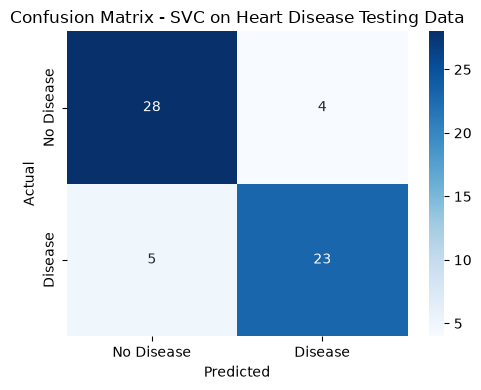

In [42]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small or imbalanced
datasets. This section adds the standard classification metrics:
- Precision: of everyone the model predicted as "Disease", how many really had heart disease?
- Recall: of everyone who really had heart disease, how many did the model catch?
- F1-score: the harmonic mean of precision and recall.
- Confusion Matrix: a table of correct vs. incorrect predictions per class.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Disease (0)", "Disease (1)"]
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Disease", "Actual: Disease"],
    columns=["Predicted: No Disease", "Predicted: Disease"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()


### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [43]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter the data of a patient
(ChestPain, ExerciseAngina, Vessels, Thal). In an interactive notebook,
running this cell can ask you to type the values with input().
In this notebook copy, we pre-fill a demo patient so the notebook can
run from top to bottom without waiting for typing.

To try your own values, replace the four lines below with:
    chestpain_input = input("Please enter ChestPain here (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
    exerciseangina_input = input("Please enter ExerciseAngina here (Yes, No): ").strip()
    vessels_input = input("Please enter Vessels here (Zero, One, Two, Three): ").strip()
    thal_input = input("Please enter Thal here (Normal, Fixed Defect, Reversible Defect): ").strip()
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
chestpain_input = "Asymptomatic"
exerciseangina_input = "Yes"
vessels_input = "Two"
thal_input = "Reversible Defect"

print(f"ChestPain: {chestpain_input}, ExerciseAngina: {exerciseangina_input}, Vessels: {vessels_input}, Thal: {thal_input}")


ChestPain: Asymptomatic, ExerciseAngina: Yes, Vessels: Two, Thal: Reversible Defect


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [44]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's input (entered as text)
and converts it into a structured feature vector (DataFrame).
"""

user_input = pd.DataFrame({
    'ChestPain': [chestpain_input],
    'ExerciseAngina': [exerciseangina_input],
    'Vessels': [vessels_input],
    'Thal': [thal_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

      ChestPain ExerciseAngina Vessels               Thal
0  Asymptomatic            Yes     Two  Reversible Defect


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [45]:
"""
Purpose of this section:
-------------------------
This part of the code encodes the user's input into numeric values
using the previously trained LabelEncoders.
"""

unseen_data_features = user_input.copy()

unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input['ChestPain'])
unseen_data_features["ExerciseAngina"] = exerciseangina_label_encoder.transform(user_input['ExerciseAngina'])
unseen_data_features["Vessels"] = vessels_label_encoder.transform(user_input['Vessels'])
unseen_data_features["Thal"] = thal_label_encoder.transform(user_input['Thal'])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   ChestPain  ExerciseAngina  Vessels  Thal
0          0               1        2     2


### Step 8.4: Load the Saved Model

In [46]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for the Application Phase.
"""

model = pickle.load(open('svc_trained_model.pkl', 'rb'))


### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [47]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a new patient (user input) has heart disease or not.
"""

predicted_heartdisease = model.predict(unseen_data_features)

if predicted_heartdisease == 1:
    prediction = "HEART DISEASE"
if predicted_heartdisease == 0:
    prediction = "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)


+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|         HEART DISEASE          |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [48]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert and testers
after they try the deployed model on a few cases.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Doctor)", "Student Tester", "Domain Expert (Doctor)"],
    "Case": [
        "Asymptomatic chest pain, exercise angina Yes, 2 vessels, Reversible Defect -> predicted HEART DISEASE",
        "Non-Anginal Pain, exercise angina No, 0 vessels, Normal -> predicted NO HEART DISEASE",
        "Any patient: the model only gives Yes or No",
    ],
    "Feedback": [
        "Makes medical sense. These are all known warning signs.",
        "Makes sense for a healthy-looking profile.",
        "Doctors want a risk percentage, not only Yes/No. Age, cholesterol and blood pressure are also missing.",
    ],
})
print(example_feedback.to_string(index=False))


              Reviewer                                                                                                  Case                                                                                               Feedback
Domain Expert (Doctor) Asymptomatic chest pain, exercise angina Yes, 2 vessels, Reversible Defect -> predicted HEART DISEASE                                                Makes medical sense. These are all known warning signs.
        Student Tester                 Non-Anginal Pain, exercise angina No, 0 vessels, Normal -> predicted NO HEART DISEASE                                                             Makes sense for a healthy-looking profile.
Domain Expert (Doctor)                                                           Any patient: the model only gives Yes or No Doctors want a risk percentage, not only Yes/No. Age, cholesterol and blood pressure are also missing.


#### Step 9.2: Make a List of Potential Improvements

In [49]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from the feedback above.
"""

improvements = [
    "Use more input attributes (age, blood pressure, cholesterol, max heart rate), not only 4",
    "Use the numeric attributes directly, with scaling, instead of only the category attributes",
    "Use more data: add the Hungarian, Switzerland and VA files from the UCI repository",
    "Show a risk percentage (probability), not only Yes/No",
    "Use cross-validation and compare other models (Random Forest, Logistic Regression)",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")


1. Use more input attributes (age, blood pressure, cholesterol, max heart rate), not only 4
2. Use the numeric attributes directly, with scaling, instead of only the category attributes
3. Use more data: add the Hungarian, Switzerland and VA files from the UCI repository
4. Show a risk percentage (probability), not only Yes/No
5. Use cross-validation and compare other models (Random Forest, Logistic Regression)


#### Step 9.3: Improve the Model Based on Feedback

In [50]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain with the improvements listed above and re-run Steps 6-7 to confirm
that the new model is better before replacing the deployed model.
"""

print("Next version: retrain with more attributes and more data, then re-evaluate before replacing svc_trained_model.pkl")


Next version: retrain with more attributes and more data, then re-evaluate before replacing svc_trained_model.pkl


## Step 10: Deploy Your Model as a Public Web App

The model is deployed as a live website with **Streamlit Community Cloud** (free), the same way as the Titanic demo.

**Files needed in the GitHub repo:**
- `app.py` - the web app
- `svc_trained_model.pkl` - the trained model saved in Step 6.4
- `requirements.txt` - the packages the app needs (use the same scikit-learn version that trained the model)

**Steps:**
1. Make a **Public** GitHub repository and upload the files above.
2. Go to https://share.streamlit.io and sign in with GitHub.
3. Click **Create app** -> **Deploy a public app from GitHub**.
4. Select the repository, branch `main`, and the main file path (`app.py`).
5. Click **Advanced settings** and choose **Python 3.11**, then click **Deploy**.
6. Copy the live link and paste it at the **top of this notebook**.

**Common problem:** `ModuleNotFoundError` usually means the Python version is too new for the pinned packages. Use Python 3.11 in the app settings.

## Conclusion
This notebook built a complete machine learning system for heart disease prediction: loading and cleaning the data, label encoding, training a Support Vector Classifier, testing, and the application phase. It also includes the feedback phase and the cloud deployment steps.

Using only 4 input attributes (chest pain type, exercise angina, number of vessels and thal result), the SVC reached an accuracy of **0.85 (85%)** on the 60 test patients. For the "Disease" class, precision is 0.85 and recall is 0.82 (see Step 7.5), so the model found 23 of the 28 sick patients in the test set and missed 5. This is a good result for a model that sees only 4 attributes. But the test set is small, and this is a **learning project only**. It must never be used for real medical decisions.